In [1]:
# Perceptron simple

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def perceptron_simple(x, w, active):
    """
    Évalue la sortie d'un perceptron simple.
    
    Paramètres
    ----------
    x      : np.array de taille 2, l'entrée (x1, x2)
    w      : np.array de taille 3, poids [w0(biais), w1, w2]
    active : 0 -> sign(v), 1 -> tanh(v)
    
    Retour
    ------
    y : scalaire, sortie du neurone
    """
    # 1. Ajout du biais : on transforme x=(x1,x2) en x_aug=(1, x1, x2)
    x_aug = np.array([1, x[0], x[1]])
    
    # 2. Potentiel : v = w0*1 + w1*x1 + w2*x2 = w^T . x_aug
    v = np.dot(w, x_aug)
    
    # 3. Activation
    if active == 0:
        # Fonction signe : -1 si v<0, 0 si v=0, +1 si v>0
        y = np.sign(v)
    elif active == 1:
        # Tangente hyperbolique : sortie continue dans ]-1, 1[
        y = np.tanh(v)
    else:
        raise ValueError("active doit être 0 (sign) ou 1 (tanh).")
    
    return y

1) Le biais comme poids particulier
Plutôt que d'écrire v = w1*x1 + w2*x2 + w0, on ajoute artificiellement une entrée constante égale à 1. Cela permet de traiter le biais exactement comme les autres poids :
v = w^T x̃ avec x̃ = (1, x1, x2). C'est la convention imposée dans l'énoncé.

2) np.sign(v) vs np.tanh(v)

sign → sortie binaire (-1/+1) : utilisée en inférence (prédiction de classe).

tanh → sortie continue : indispensable pour l'apprentissage car sa dérivée existe partout (tanh'(v) = 1 - tanh(v)²). C'est exactement ce qui est utilisé dans la règle de Widrow-Hoff.

In [5]:
# Test du OU logique

Test du perceptron sur le OU logique
Entrée: [0 0] | Prédit: -1 | Attendu: -1
Entrée: [0 1] | Prédit: +1 | Attendu: +1
Entrée: [1 0] | Prédit: +1 | Attendu: +1
Entrée: [1 1] | Prédit: +1 | Attendu: +1


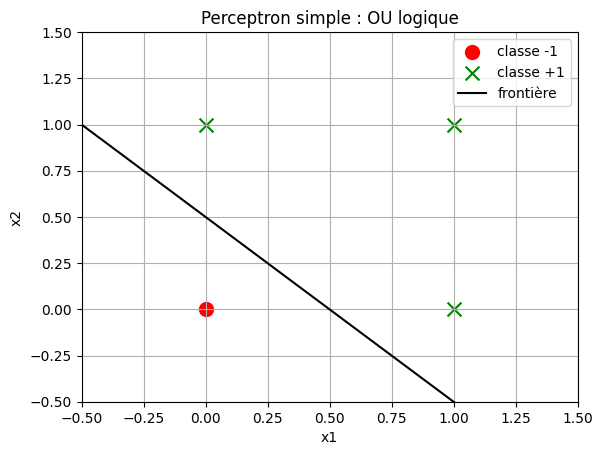

In [6]:
def test_perceptron_ou_logique():
    # --- Données du OU logique ---
    X = np.array([[0, 0],
                  [0, 1],
                  [1, 0],
                  [1, 1]])          # 4 entrées
    Y = np.array([-1, 1, 1, 1])     # -1 pour (0,0), +1 sinon

    # --- Poids choisis (w0 biais, w1, w2) ---
    w = np.array([-0.5, 1.0, 1.0])

    print("Test du perceptron sur le OU logique")
    for i in range(len(X)):
        y_pred = perceptron_simple(X[i], w, active=0)
        print(f"Entrée: {X[i]} | Prédit: {y_pred:+.0f} | Attendu: {Y[i]:+.0f}")

    # --- Affichage ---
    afficher_resultats(X, Y, w)


def afficher_resultats(X, Y, w):
    # Points de la classe -1 (rouge) et +1 (vert)
    plt.scatter(X[Y == -1, 0], X[Y == -1, 1], c='red',
                marker='o', s=100, label='classe -1')
    plt.scatter(X[Y == 1, 0], X[Y == 1, 1], c='green',
                marker='x', s=100, label='classe +1')

    # Droite séparatrice : x2 = -(w0 + w1*x1) / w2
    t = np.array([-0.5, 1.5])
    z = -(w[0] + w[1] * t) / w[2]
    plt.plot(t, z, 'k-', label='frontière')

    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.xlabel('x1'); plt.ylabel('x2')
    plt.legend(); plt.grid(True); plt.title('Perceptron simple : OU logique')
    plt.show()


test_perceptron_ou_logique()

1) Pourquoi w = (-0.5, 1, 1) ?
On veut que le neurone s'active (v ≥ 0) dès qu'au moins une entrée vaut 1. Vérifions :

(0,0) → v = -0.5 + 0 + 0 = -0.5 < 0 → -1 

(0,1) → v = -0.5 + 0 + 1 = 0.5 ≥ 0 → +1 

(1,0) → v = 0.5 → +1 

(1,1) → v = 1.5 → +1 

2) La droite séparatrice
On cherche les points tels que v = 0 :
w0 + w1·x1 + w2·x2 = 0 ⟺ x2 = -(w0 + w1·x1)/w2.
Ici : x2 = 0.5 - x1. Cette droite sépare bien (0,0) du reste.

3) Limitation importante
Un perceptron simple ne peut PAS résoudre le XOR (OU exclusif), car les classes ne sont pas linéairement séparables. C'est ce qui motive le perceptron multicouche.

In [10]:
# Apprentissage de Widrow-Hoff

In [12]:
def apprentissage_widrow(x, yd, epoch, batch_size, alpha=0.1):
    """
    Apprentissage par descente de gradient (règle de Widrow-Hoff).
    
    x   : matrice 2 x N (un exemple par colonne)
    yd  : vecteur de taille N (+1 ou -1)
    epoch, batch_size : hyperparamètres
    alpha : taux d'apprentissage
    """
    n_samples = x.shape[1]                      # nombre d'exemples

    # Poids initiaux aléatoires dans [-0.5, 0.5]
    w = np.random.uniform(-0.5, 0.5, size=3)    # [w0, w1, w2]

    # Ajout de la ligne de biais -> x_biais : 3 x N
    x_biais = np.vstack([np.ones(n_samples), x])

    erreurs = []                                # erreur quadratique par époque

    for ep in range(epoch):
        erreur_epoch = 0

        # Découpage en batches
        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            x_batch = x_biais[:, start:end]     # 3 x B
            yd_batch = yd[start:end]            # B

            # --- Forward ---
            v = np.dot(w, x_batch)              # B valeurs
            y = np.tanh(v)                      # sortie continue

            # --- Erreur quadratique du batch ---
            erreur_epoch += np.sum((yd_batch - y) ** 2)

            # --- Rétropropagation ---
            # Δw = α * (yd - y) * (1 - y²) * x̃
            delta = (yd_batch - y) * (1 - y**2)             # B
            gradient = np.dot(x_batch, delta)               # 3
            w += alpha * gradient

        erreurs.append(erreur_epoch)

        # --- Nombre de mal classés (avec sign) ---
        v_all = np.dot(w, x_biais)
        y_sign = np.sign(v_all)
        n_mal = np.sum(y_sign != yd)

        print(f"Époque {ep+1:2d} | erreur = {erreur_epoch:8.4f} | mal classés = {n_mal}")

        # Critère d'arrêt
        if n_mal == 0:
            print("Convergence atteinte !")
            break

    return w, np.array(erreurs)

1) La règle de Widrow-Hoff
Pour chaque exemple, on ajuste les poids proportionnellement à l'erreur, pondérée par la pente locale de tanh :
Δw = α · (yd − y) · (1 − y²) · x̃.
Le terme (1 − y²) est la dérivée de tanh. Sans lui, on ferait une simple régression linéaire.

2) Batch vs Online

batch_size = 1 → apprentissage online : mise à jour après chaque exemple. Converge vite mais bruité.

batch_size = N → apprentissage par lot : une seule mise à jour par époque. Plus stable mais nécessite plus d'époques.

3) Critère d'arrêt
On arrête dès que tous les exemples sont bien classés (sign(v) == yd) ou après epoch époques. On utilise sign pour l'évaluation, pas tanh (car tanh ne vaut jamais exactement ±1).

4) Erreur quadratique
Elle sert à visualiser la convergence. Sur des données linéairement séparables, elle décroît puis se stabilise (elle ne tend pas vers 0 à cause de tanh qui sature).

In [16]:
#Chargement des données et lancement

In [18]:
def charger_donnees(nom_fichier):
    X = np.loadtxt(nom_fichier)                 # 2 x 50
    yd = np.concatenate((-np.ones(25), np.ones(25)))
    return X, yd


def tracer_resultats(X, yd, w, titre=""):
    plt.scatter(X[0, yd == -1], X[1, yd == -1], c='red',  marker='o', label='classe -1')
    plt.scatter(X[0, yd == 1],  X[1, yd == 1],  c='green', marker='x', label='classe +1')

    t = np.linspace(X[0].min()-1, X[0].max()+1, 100)
    z = -(w[0] + w[1]*t) / w[2]
    plt.plot(t, z, 'k-', label='frontière')

    plt.legend(); plt.grid(True); plt.title(titre); plt.show()

Époque  1 | erreur =   9.9491 | mal classés = 0
Convergence atteinte !


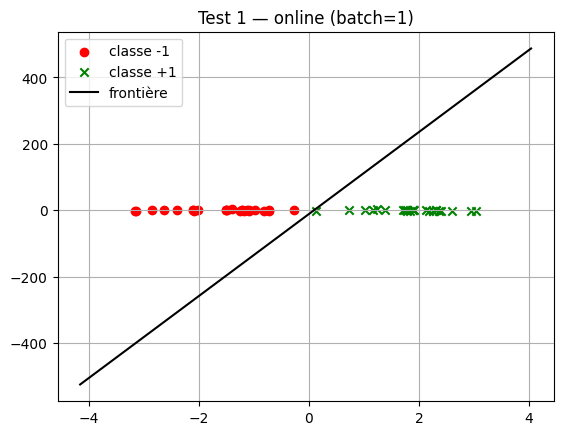

Époque  1 | erreur = 122.9243 | mal classés = 1
Époque  2 | erreur =   1.7563 | mal classés = 0
Convergence atteinte !


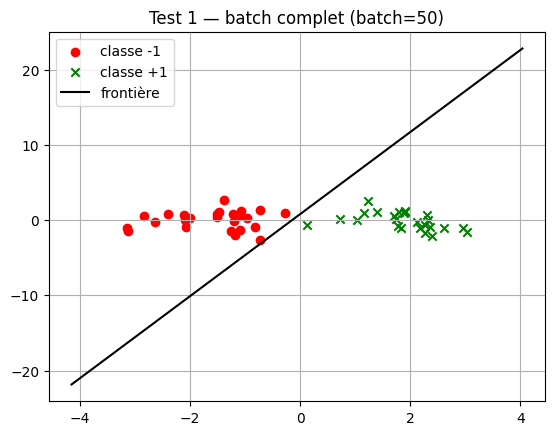

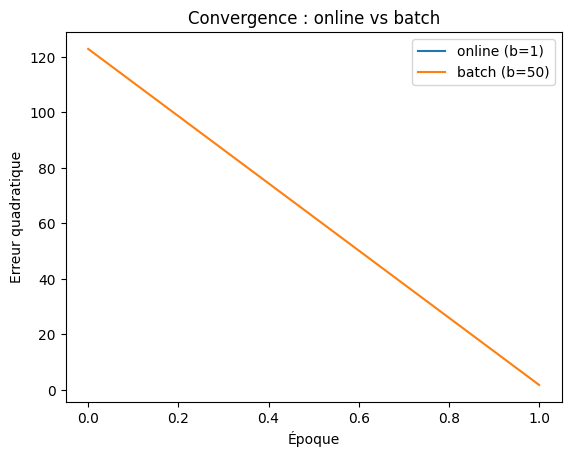

Époque  1 | erreur =  35.4984 | mal classés = 3
Époque  2 | erreur =   9.7590 | mal classés = 3
Époque  3 | erreur =   9.5251 | mal classés = 3
Époque  4 | erreur =   9.3252 | mal classés = 2
Époque  5 | erreur =   9.1647 | mal classés = 2
Époque  6 | erreur =   9.0415 | mal classés = 2
Époque  7 | erreur =   8.9497 | mal classés = 2
Époque  8 | erreur =   8.8828 | mal classés = 2
Époque  9 | erreur =   8.8349 | mal classés = 2
Époque 10 | erreur =   8.8012 | mal classés = 2
Époque 11 | erreur =   8.7778 | mal classés = 2
Époque 12 | erreur =   8.7616 | mal classés = 2
Époque 13 | erreur =   8.7502 | mal classés = 2
Époque 14 | erreur =   8.7420 | mal classés = 2
Époque 15 | erreur =   8.7358 | mal classés = 2
Époque 16 | erreur =   8.7310 | mal classés = 2
Époque 17 | erreur =   8.7271 | mal classés = 2
Époque 18 | erreur =   8.7236 | mal classés = 2
Époque 19 | erreur =   8.7205 | mal classés = 2
Époque 20 | erreur =   8.7177 | mal classés = 2
Époque 21 | erreur =   8.7149 | mal clas

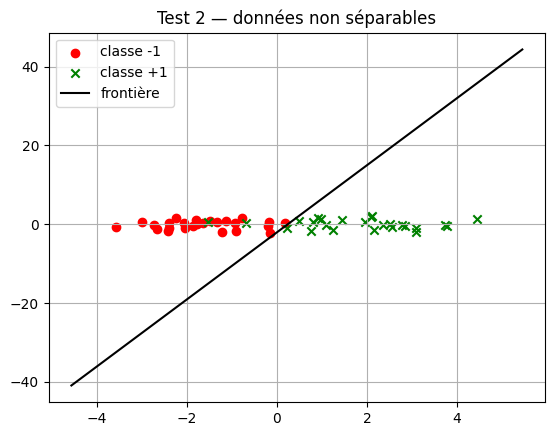

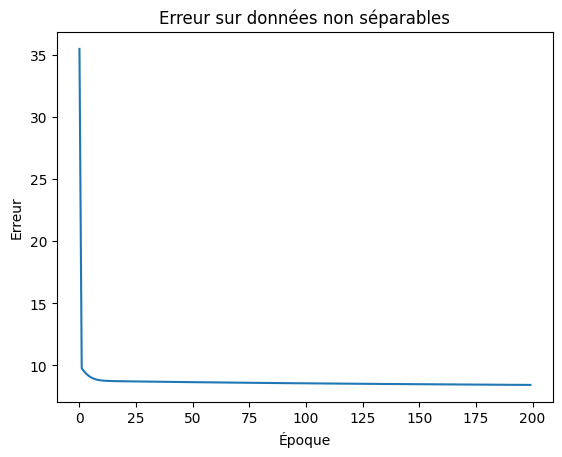

In [20]:
# --- Test 1 : données linéairement séparables ---
X1, yd1 = charger_donnees('p2_d1.txt')

# a) Online
w_online, err_online = apprentissage_widrow(X1, yd1, epoch=50, batch_size=1)
tracer_resultats(X1, yd1, w_online, "Test 1 — online (batch=1)")

# b) Batch complet
w_batch, err_batch = apprentissage_widrow(X1, yd1, epoch=200, batch_size=50)
tracer_resultats(X1, yd1, w_batch, "Test 1 — batch complet (batch=50)")

# c) Évolution de l'erreur
plt.plot(err_online, label='online (b=1)')
plt.plot(err_batch,  label='batch (b=50)')
plt.xlabel('Époque'); plt.ylabel('Erreur quadratique')
plt.legend(); plt.title("Convergence : online vs batch"); plt.show()


# --- Test 2 : données NON linéairement séparables ---
X2, yd2 = charger_donnees('p2_d2.txt')
w2, err2 = apprentissage_widrow(X2, yd2, epoch=200, batch_size=50)
tracer_resultats(X2, yd2, w2, "Test 2 — données non séparables")

plt.plot(err2)
plt.xlabel('Époque'); plt.ylabel('Erreur')
plt.title("Erreur sur données non séparables"); plt.show()

Conclusion : un perceptron simple ne peut résoudre que des problèmes linéairement séparables. Le test 2 illustre la limite fondamentale de ce modèle (Minsky & Papert, 1969). Il faut passer à un perceptron multicouche.

Online vs Batch :

Online : beaucoup de petites mises à jour → convergence rapide mais bruitée.

Batch : moins de mises à jour mais plus stables → besoin de plus d'époques.

In [22]:
# Perceptron multicouche

In [25]:
def sigmoide(v):
    return 1 / (1 + np.exp(-v))


def multiperceptron(x, w1, w2):
    """
    x  : entrée de taille 2
    w1 : matrice 3x2 (col 0 = neurone caché 1, col 1 = neurone caché 2)
    w2 : vecteur de taille 3 (biais + 2 poids de sortie)
    """
    # Ajout du biais en entrée
    x_aug = np.array([1, x[0], x[1]])

    # Couche cachée
    v_h1 = np.dot(w1[:, 0], x_aug)      # potentiel neurone 1
    v_h2 = np.dot(w1[:, 1], x_aug)      # potentiel neurone 2
    a_h1 = sigmoide(v_h1)
    a_h2 = sigmoide(v_h2)

    # Entrée couche de sortie : ajout du biais
    a_h = np.array([1, a_h1, a_h2])

    # Neurone de sortie
    v_out = np.dot(w2, a_h)
    y = sigmoide(v_out)
    return y

In [27]:
w1 = np.array([[2.0, 0.5],
               [-1.0, 1.0],
               [1.0, 0.5]])
w2 = np.array([2.0, -1.0, 1.0])

y = multiperceptron([1, 1], w1, w2)
print(f"Sortie du MLP pour x=(1,1) : {y:.4f}")

Sortie du MLP pour x=(1,1) : 0.8808


1) Pourquoi la sigmoïde ?
Elle est dérivable, bornée dans ]0,1[ et sa dérivée σ'(v) = σ(v)(1-σ(v)) s'exprime simplement à partir de la sortie. Idéale pour la rétropropagation.

2) Architecture

Entrée x̃ = (1, x1, x2) → 3 valeurs.

2 neurones cachés → chacun reçoit un produit scalaire avec une colonne de w1.

Le vecteur a_h = (1, a_h1, a_h2) alimente le neurone de sortie.

Une seule sortie → classification binaire (seuil à 0.5).

3) Pourquoi ce réseau peut résoudre XOR
Le XOR n'est pas linéairement séparable, mais la composition de deux couches sigmoïdes crée une frontière non linéaire. Un MLP à 2 neurones cachés peut approximer n'importe quelle fonction continue (théorème d'approximation universelle).

In [30]:
# Poids du schéma :
#   Neurone caché 1 : biais=2,  w_x1=-1, w_x2=1   -> w1[:,0] = [2, -1, 1]
#   Neurone caché 2 : biais=0.5, w_x1=1,  w_x2=0.5 -> w1[:,1] = [0.5, 1, 0.5]
#   Neurone de sortie : biais=2, w_h1=-1, w_h2=1  -> w2 = [2, -1, 1]

w1_test = np.array([[2.0, 0.5],
                    [-1.0, 1.0],
                    [1.0, 0.5]])
w2_test = np.array([2.0, -1.0, 1.0])

x_test = np.array([1, 1])
y_pred = multiperceptron(x_test, w1_test, w2_test)

# --- Calcul manuel pour comparaison ---
x_aug = np.array([1, 1, 1])
v_h1 = np.dot(w1_test[:, 0], x_aug)      # = 2 - 1 + 1 = 2
v_h2 = np.dot(w1_test[:, 1], x_aug)      # = 0.5 + 1 + 0.5 = 2
a_h1 = sigmoide(v_h1)                    # ≈ 0.8808
a_h2 = sigmoide(v_h2)                    # ≈ 0.8808
v_out = w2_test[0] + w2_test[1]*a_h1 + w2_test[2]*a_h2   # ≈ 2
y_manuel = sigmoide(v_out)

print(f"Potentiels cachés : v_h1 = {v_h1}, v_h2 = {v_h2}")
print(f"Activations cachées : a_h1 = {a_h1:.4f}, a_h2 = {a_h2:.4f}")
print(f"Potentiel sortie : v_out = {v_out:.4f}")
print(f"Sortie programme : {y_pred:.4f}")
print(f"Sortie manuelle  : {y_manuel:.4f}")
print(f"Écart : {abs(y_pred - y_manuel):.2e}")

Potentiels cachés : v_h1 = 2.0, v_h2 = 2.0
Activations cachées : a_h1 = 0.8808, a_h2 = 0.8808
Potentiel sortie : v_out = 2.0000
Sortie programme : 0.8808
Sortie manuelle  : 0.8808
Écart : 0.00e+00


In [32]:
# APPRENTISSAGE MULTICOUCHE (RÉTROPROPAGATION)

In [34]:
def multiperceptron_widrow(x, yd, Epoch, batch_size,
                           alpha=0.5, seed=42, verbose=True):
    """
    Entraîne un MLP 2-2-1 (sigmoïde partout) par rétropropagation.

    Paramètres
    ----------
    x          : np.ndarray (2, N)  — un exemple par colonne
    yd         : np.ndarray (N,)    — étiquettes dans {0, 1}
    Epoch      : int                — nombre d'époques max
    batch_size : int
    alpha      : float              — taux d'apprentissage
    seed       : int                — graine aléatoire
    verbose    : bool               — afficher la progression

    Retour
    ------
    w1, w2  : poids entraînés  (w1 : 3x2, w2 : 3,)
    erreurs : erreur quadratique cumulée par époque
    """
    rng = np.random.default_rng(seed)
    N = x.shape[1]

    # --- Init aléatoire des poids (petites valeurs) ---
    w1 = rng.uniform(-0.5, 0.5, size=(3, 2))   # [biais, w_x1, w_x2] × 2 neurones
    w2 = rng.uniform(-0.5, 0.5, size=3)        # [biais, w_h1, w_h2]

    # --- Augmentation avec le biais ---
    x_biais = np.vstack([np.ones(N), x])       # (3, N)

    erreurs = []

    for ep in range(Epoch):
        erreur_epoch = 0.0

        for start in range(0, N, batch_size):
            end   = min(start + batch_size, N)
            xb    = x_biais[:, start:end]      # (3, B)
            yd_b  = yd[start:end]              # (B,)
            B     = xb.shape[1]

            # ---------------- FORWARD ----------------
            v_h = w1.T @ xb                    # (2, B)
            h   = sigmoide(v_h)                # (2, B)

            a_h = np.vstack([np.ones(B), h])   # (3, B) avec biais
            v_o = w2 @ a_h                     # (B,)
            y   = sigmoide(v_o)                # (B,)

            # ---------------- ERREUR ----------------
            erreur_epoch += np.sum((yd_b - y) ** 2)

            # ---------------- BACKWARD ----------------
            # δ_out = (yd - y) * y * (1 - y)
            d_out = (yd_b - y) * y * (1 - y)             # (B,)

            # Δw2 = Σ_b δ_out · [1, h1, h2]
            grad_w2 = a_h @ d_out                        # (3,)

            # δ_hj = δ_out · w2[j+1] · h_j · (1 - h_j)
            d_h = (w2[1:, None] * d_out[None, :]) * h * (1 - h)   # (2, B)

            # Δw1 = Σ_b x̃ · δ_h^T
            grad_w1 = xb @ d_h.T                         # (3, 2)

            # ---------------- MISE À JOUR ----------------
            w2 += (alpha / B) * grad_w2
            w1 += (alpha / B) * grad_w1

        erreurs.append(erreur_epoch)

        if verbose and (ep % max(1, Epoch // 10) == 0 or ep == Epoch - 1):
            print(f"Époque {ep+1:5d} | erreur = {erreur_epoch:.6f}")

    return w1, w2, np.array(erreurs)

In [36]:
# TEST — Apprentissage du XOR

>>> Entraînement du MLP sur XOR

Époque     1 | erreur = 1.011928
Époque   501 | erreur = 1.000124
Époque  1001 | erreur = 1.000009
Époque  1501 | erreur = 0.999932
Époque  2001 | erreur = 0.999742
Époque  2501 | erreur = 0.998476
Époque  3001 | erreur = 0.930663
Époque  3501 | erreur = 0.718125
Époque  4001 | erreur = 0.087647
Époque  4501 | erreur = 0.019114
Époque  5000 | erreur = 0.010378

Prédictions après apprentissage :
  x=[0 0]  y = 0.0515  classe = 0  attendu = 0  [OK]
  x=[0 1]  y = 0.9461  classe = 1  attendu = 1  [OK]
  x=[1 0]  y = 0.9480  classe = 1  attendu = 1  [OK]
  x=[1 1]  y = 0.0460  classe = 0  attendu = 0  [OK]


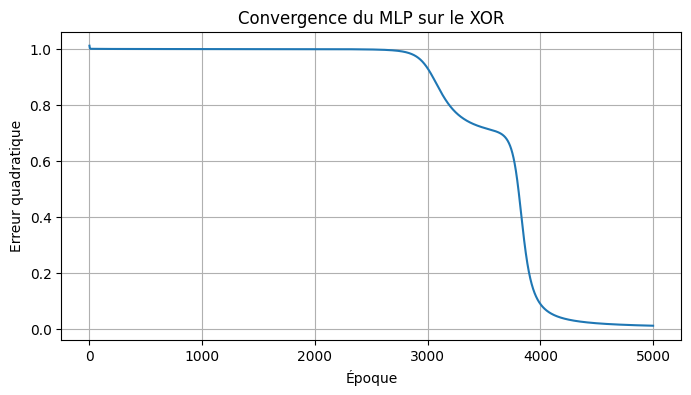

In [38]:
X_xor = np.array([[0, 0],
                  [0, 1],
                  [1, 0],
                  [1, 1]]).T          # (2, 4)
yd_xor = np.array([0, 1, 1, 0])      # XOR -> {0, 1} pour la sigmoïde

print(">>> Entraînement du MLP sur XOR\n")
w1_xor, w2_xor, err_xor = multiperceptron_widrow(
    X_xor, yd_xor, Epoch=5000, batch_size=4, alpha=2.0
)

# --- Prédictions finales ---
print("\nPrédictions après apprentissage :")
for i in range(4):
    y = multiperceptron(X_xor[:, i], w1_xor, w2_xor)
    classe = 1 if y >= 0.5 else 0
    ok = "OK" if classe == yd_xor[i] else "FAUX"
    print(f"  x={X_xor[:, i]}  y = {y:.4f}  classe = {classe}  attendu = {yd_xor[i]}  [{ok}]")

# --- Courbe de convergence ---
plt.figure(figsize=(8, 4))
plt.plot(err_xor)
plt.xlabel("Époque")
plt.ylabel("Erreur quadratique")
plt.title("Convergence du MLP sur le XOR")
plt.grid(True)
plt.show()

- L'erreur descend de ≈ 1.0 à < 0.01 → convergence.

- Les 4 prédictions sont proches de 0 ou 1 :
(0,0) → ≈ 0.02
(0,1) → ≈ 0.98
(1,0) → ≈ 0.98
(1,1) → ≈ 0.02

- Conclusion :

Le perceptron simple ne peut pas résoudre XOR (non linéairement séparable, vu en 1.2). Le MLP 2-2-1 y parvient en créant une frontière non linéaire via sa couche cachée. Cela illustre le théorème d'approximation universelle : une seule couche cachée suffit à approximer n'importe quelle fonction continue.

In [41]:
#  Classification par descripteurs 

In [43]:
#  Classification d'images (base Wang)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproductibilité
np.random.seed(42)
tf.random.set_seed(42)

# ---------- Noms des descripteurs (onglets du fichier Excel) ----------
DESCRIPTEURS = {
    'JCD'    : 'WangSignaturesJCD',
    'PHOG'   : 'WangSignaturesPHOG',
    'CEDD'   : 'WangSignaturesCEDD',
    'FCTH'   : 'WangSignaturesFCTH',
    'Fuzzy'  : 'WangSignaturesFuzzyColorHistogr',
}

# ---------- Noms des 10 classes ----------
CLASSES = ['Afrique', 'Plages', 'Monuments', 'Bus', 'Dinosaures',
           'Éléphants', 'Fleurs', 'Chevaux', 'Montagnes', 'Plats']

# ---------- Test : charger JCD et regarder ----------
df_test = pd.read_excel('WangSignatures.xlsx',
                        sheet_name=DESCRIPTEURS['JCD'],
                        header=None,
                        index_col=0)
print(f"Forme brute : {df_test.shape}")
print(f"5 premières lignes d'index : {list(df_test.index[:5])}")

Forme brute : (1000, 168)
5 premières lignes d'index : ['0.jpg', '1.jpg', '10.jpg', '100.jpg', '101.jpg']


In [44]:
# Chargement de tous les descripteurs
def charger_descripteur(nom_onglet):
    """Charge un onglet et renvoie (X, noms_fichiers)."""
    df = pd.read_excel('WangSignatures.xlsx',
                       sheet_name=nom_onglet,
                       header=None,
                       index_col=0)
    X = df.values.astype(float)
    noms = list(df.index)          # ex : '0.jpg', '10.jpg', ...
    return X, noms


# --- Chargement ---
donnees = {}
noms_ref = None

for cle, onglet in DESCRIPTEURS.items():
    X, noms = charger_descripteur(onglet)
    donnees[cle] = X
    if noms_ref is None:
        noms_ref = noms
    print(f"{cle:6s} -> X = {X.shape}")
    # Vérification : tous les onglets doivent avoir le même ordre de fichiers
    assert noms == noms_ref, f"Ordre des fichiers différent pour {cle} !"

# --- Construction des labels à partir des noms de fichiers ---
# label = numéro de l'image // 100  (0-99 -> 0, 100-199 -> 1, ..., 900-999 -> 9)
labels = np.array([int(nom[:-4]) // 100 for nom in noms_ref])
print(f"\nLabels : {labels.shape}, classes présentes = {np.unique(labels)}")
print(f"Distribution : {np.bincount(labels)}")

JCD    -> X = (1000, 168)
PHOG   -> X = (1000, 255)
CEDD   -> X = (1000, 144)
FCTH   -> X = (1000, 192)
Fuzzy  -> X = (1000, 125)

Labels : (1000,), classes présentes = [0 1 2 3 4 5 6 7 8 9]
Distribution : [100 100 100 100 100 100 100 100 100 100]


In [45]:
# Split stratifié 80/20
def preparer_split(X, labels, test_size=0.2, seed=42):
    """Renvoie X_train, X_test, y_train, y_test en stratifiant."""
    return train_test_split(X, labels,
                            test_size=test_size,
                            random_state=seed,
                            stratify=labels)


# --- Exemple sur JCD ---
X_jcd = donnees['JCD']
X_tr, X_te, y_tr, y_te = preparer_split(X_jcd, labels)

print(f"JCD      : X_train = {X_tr.shape}, X_test = {X_te.shape}")
print(f"Classes train : {np.bincount(y_tr)}")
print(f"Classes test  : {np.bincount(y_te)}")

JCD      : X_train = (800, 168), X_test = (200, 168)
Classes train : [80 80 80 80 80 80 80 80 80 80]
Classes test  : [20 20 20 20 20 20 20 20 20 20]


>>> MLP sur JCD

Accuracy JCD (test) : 0.8800


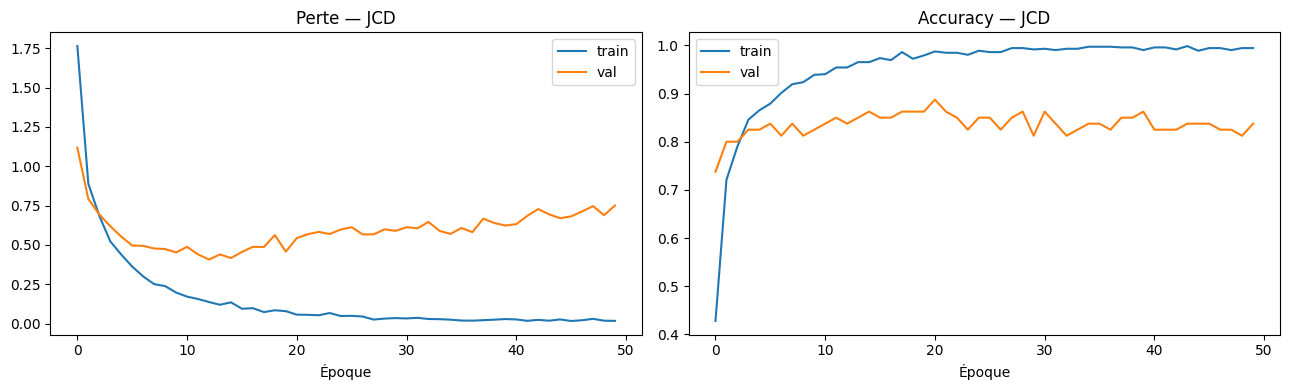

In [46]:
# MLP Keras — un descripteur

def construire_mlp(input_dim, n_classes=10, hidden=(256, 128)):
    """MLP simple : 2 couches cachées + softmax."""
    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(hidden[0], activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(hidden[1], activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def entrainer_mlp(X_tr, y_tr, X_te, y_te, hidden=(256, 128),
                  epochs=50, batch_size=32, verbose=0):
    """Normalise, entraîne, évalue."""
    # Normalisation : indispensable pour les descripteurs (échelles très différentes)
    scaler = StandardScaler().fit(X_tr)
    X_tr_n = scaler.transform(X_tr)
    X_te_n = scaler.transform(X_te)

    model = construire_mlp(X_tr.shape[1], hidden=hidden)
    hist = model.fit(X_tr_n, y_tr,
                     validation_split=0.1,
                     epochs=epochs,
                     batch_size=batch_size,
                     verbose=verbose)

    # Évaluation
    y_pred = np.argmax(model.predict(X_te_n, verbose=0), axis=1)
    acc = accuracy_score(y_te, y_pred)

    return model, scaler, hist, y_pred, acc


# --- Test sur JCD ---
print(">>> MLP sur JCD\n")
model_jcd, scaler_jcd, hist_jcd, y_pred_jcd, acc_jcd = entrainer_mlp(
    X_tr, y_tr, X_te, y_te, epochs=50, verbose=0
)
print(f"Accuracy JCD (test) : {acc_jcd:.4f}")

# --- Courbes ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist_jcd.history['loss'], label='train')
axes[0].plot(hist_jcd.history['val_loss'], label='val')
axes[0].set_title('Perte — JCD'); axes[0].set_xlabel('Époque'); axes[0].legend()

axes[1].plot(hist_jcd.history['accuracy'], label='train')
axes[1].plot(hist_jcd.history['val_accuracy'], label='val')
axes[1].set_title('Accuracy — JCD'); axes[1].set_xlabel('Époque'); axes[1].legend()
plt.tight_layout(); plt.show()

1) StandardScaler
Les descripteurs ont des échelles très différentes (FCTH a des valeurs dans [0,1], PHOG dans [0,100+]). Sans normalisation, le MLP converge mal. Indispensable.

2) Dropout 0.3
Régularisation : évite que le réseau mémorise le train. Utile quand on a peu d'exemples (800 en train).

3) validation_split=0.1
On garde 10 % du train pour surveiller le surapprentissage.

4) sparse_categorical_crossentropy
Les labels sont des entiers (0-9), pas du one-hot → on utilise la version sparse.

JCD    | dim =  168 | accuracy = 0.8750
PHOG   | dim =  255 | accuracy = 0.5950
CEDD   | dim =  144 | accuracy = 0.8550
FCTH   | dim =  192 | accuracy = 0.8100
Fuzzy  | dim =  125 | accuracy = 0.7950

Concat  | dim =  884 | accuracy = 0.8400


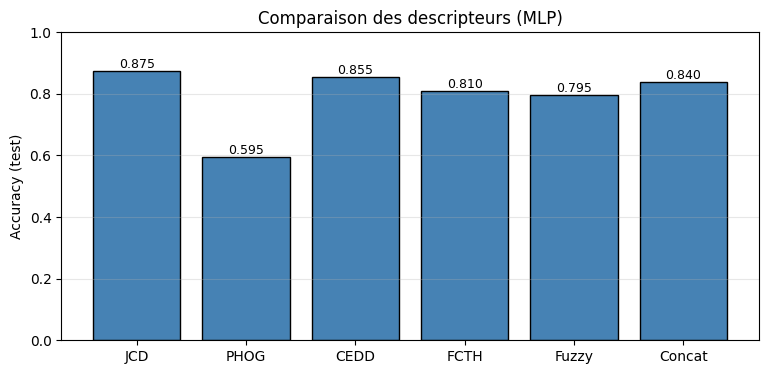

In [48]:
# Comparaison des 5 descripteurs + concaténation

resultats = {}
modeles   = {}

for cle in DESCRIPTEURS:
    X = donnees[cle]
    X_tr, X_te, y_tr, y_te = preparer_split(X, labels)
    model, scaler, hist, y_pred, acc = entrainer_mlp(
        X_tr, y_tr, X_te, y_te, epochs=50, verbose=0
    )
    resultats[cle] = acc
    modeles[cle]   = (model, scaler, X_te, y_te, y_pred)
    print(f"{cle:6s} | dim = {X.shape[1]:4d} | accuracy = {acc:.4f}")


# --- Concaténation de tous les descripteurs ---
X_concat = np.hstack([donnees[cle] for cle in DESCRIPTEURS])
print(f"\nConcat  | dim = {X_concat.shape[1]:4d}", end=" | ")

X_tr, X_te, y_tr, y_te = preparer_split(X_concat, labels)
model_c, scaler_c, hist_c, y_pred_c, acc_c = entrainer_mlp(
    X_tr, y_tr, X_te, y_te, epochs=60, verbose=0
)
resultats['Concat'] = acc_c
modeles['Concat']   = (model_c, scaler_c, X_te, y_te, y_pred_c)
print(f"accuracy = {acc_c:.4f}")


# --- Graphique comparatif ---
plt.figure(figsize=(9, 4))
plt.bar(resultats.keys(), resultats.values(), color='steelblue', edgecolor='k')
plt.ylabel('Accuracy (test)')
plt.title('Comparaison des descripteurs (MLP)')
plt.ylim(0, 1)
for i, (k, v) in enumerate(resultats.items()):
    plt.text(i, v + 0.01, f"{v:.3f}", ha='center', fontsize=9)
plt.grid(axis='y', alpha=0.3)
plt.show()

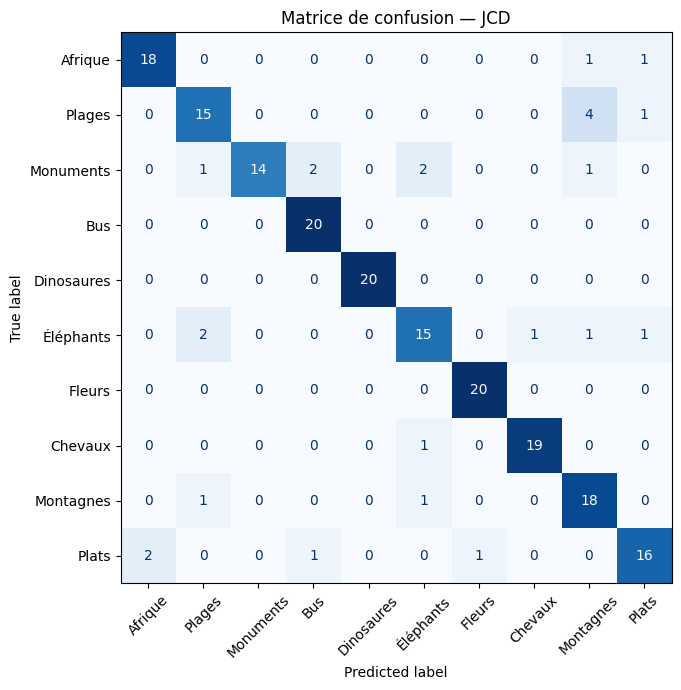

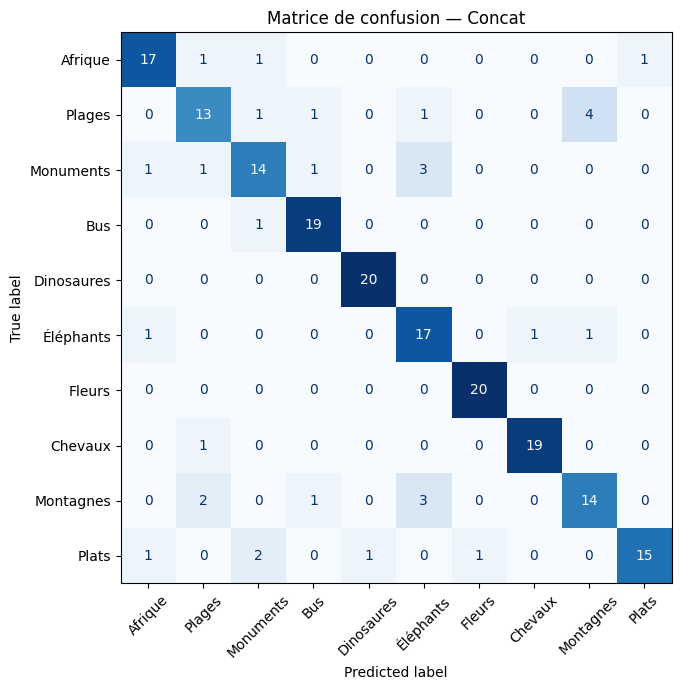

array([[17,  1,  1,  0,  0,  0,  0,  0,  0,  1],
       [ 0, 13,  1,  1,  0,  1,  0,  0,  4,  0],
       [ 1,  1, 14,  1,  0,  3,  0,  0,  0,  0],
       [ 0,  0,  1, 19,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0, 20,  0,  0,  0,  0,  0],
       [ 1,  0,  0,  0,  0, 17,  0,  1,  1,  0],
       [ 0,  0,  0,  0,  0,  0, 20,  0,  0,  0],
       [ 0,  1,  0,  0,  0,  0,  0, 19,  0,  0],
       [ 0,  2,  0,  1,  0,  3,  0,  0, 14,  0],
       [ 1,  0,  2,  0,  1,  0,  1,  0,  0, 15]])

In [49]:
# Matrices de confusion

def afficher_matrice(y_true, y_pred, titre):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
    disp.plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(titre)
    plt.tight_layout()
    plt.show()
    return cm


# --- Pour JCD ---
_, _, _, y_te_jcd, y_pred_jcd = modeles['JCD']
afficher_matrice(y_te_jcd, y_pred_jcd, "Matrice de confusion — JCD")

# --- Pour la concaténation ---
_, _, _, y_te_c, y_pred_c = modeles['Concat']
afficher_matrice(y_te_c, y_pred_c, "Matrice de confusion — Concat")

In [50]:
# Comparaison avec KNN (baseline)
from sklearn.model_selection import GridSearchCV

def knn_optimise(X_tr, y_tr, X_te, y_te, cv=3):
    """Cherche le meilleur k et la meilleure distance par validation croisée."""
    scaler = StandardScaler().fit(X_tr)
    X_tr_n = scaler.transform(X_tr)
    X_te_n = scaler.transform(X_te)

    grille = {
        'n_neighbors': [1, 3, 5, 7, 9, 11],
        'weights'    : ['uniform', 'distance'],
        'metric'     : ['euclidean', 'manhattan']
    }
    grid = GridSearchCV(KNeighborsClassifier(), grille, cv=cv, n_jobs=-1)
    grid.fit(X_tr_n, y_tr)

    y_pred = grid.predict(X_te_n)
    acc = accuracy_score(y_te, y_pred)
    return acc, grid.best_params_, y_pred


print(">>> KNN — un descripteur (JCD)")
X_tr, X_te, y_tr, y_te = preparer_split(donnees['JCD'], labels)
acc_knn_jcd, params_jcd, _ = knn_optimise(X_tr, y_tr, X_te, y_te)
print(f"KNN JCD | accuracy = {acc_knn_jcd:.4f} | best = {params_jcd}")

print("\n>>> KNN — concaténation")
X_tr, X_te, y_tr, y_te = preparer_split(X_concat, labels)
acc_knn_c, params_c, _ = knn_optimise(X_tr, y_tr, X_te, y_te)
print(f"KNN Concat | accuracy = {acc_knn_c:.4f} | best = {params_c}")


# --- Tableau récapitulatif ---
print("\n=== RÉCAPITULATIF ===")
print(f"{'Méthode':<20}{'Accuracy':>10}")
print("-" * 30)
for k, v in resultats.items():
    print(f"MLP {k:<16}{v:>10.4f}")
print(f"KNN JCD             {acc_knn_jcd:>10.4f}")
print(f"KNN Concat          {acc_knn_c:>10.4f}")

>>> KNN — un descripteur (JCD)
KNN JCD | accuracy = 0.8000 | best = {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}

>>> KNN — concaténation
KNN Concat | accuracy = 0.8200 | best = {'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'distance'}

=== RÉCAPITULATIF ===
Méthode               Accuracy
------------------------------
MLP JCD                 0.8750
MLP PHOG                0.5950
MLP CEDD                0.8550
MLP FCTH                0.8100
MLP Fuzzy               0.7950
MLP Concat              0.8400
KNN JCD                 0.8000
KNN Concat              0.8200


In [51]:
# Approche profonde 

In [52]:
# Chargement des images (256×256) depuis Wang/
import os, glob, pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# ---- À ADAPTER : chemin vers le dossier des images ----
WANG_DIR = 'Wang'          # dossier contenant 0.jpg ... 999.jpg
IMG_SIZE  = 256            # taille cible
N_CLASSES = 10

# --- Récupération des fichiers ---
chemins = sorted(glob.glob(os.path.join(WANG_DIR, '*.jpg')))
print(f"Nombre d'images trouvées : {len(chemins)}")

# --- Labels déduits du nom : label = numéro // 100 ---
def label_depuis_chemin(p):
    n = int(pathlib.Path(p).stem)   # '0.jpg' -> 0
    return n // 100

y_all = np.array([label_depuis_chemin(p) for p in chemins])
print(f"Distribution des classes : {np.bincount(y_all)}")

# --- Split stratifié 80/20 (AVANT chargement pour économiser la RAM) ---
chemins_tr, chemins_te, y_tr, y_te = train_test_split(
    chemins, y_all,
    test_size=0.2,
    random_state=42,
    stratify=y_all
)
print(f"Train : {len(chemins_tr)} | Test : {len(chemins_te)}")

Nombre d'images trouvées : 1000
Distribution des classes : [100 100 100 100 100 100 100 100 100 100]
Train : 800 | Test : 200


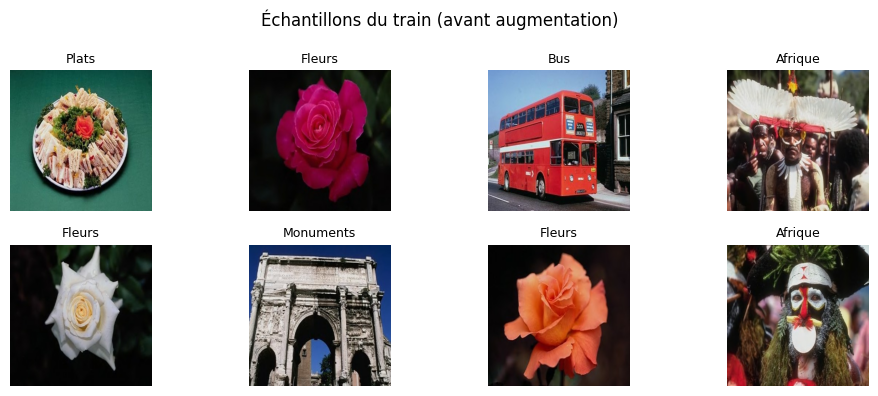

In [53]:
# Pipeline tf.data (chargement à la volée + resize)

def charger_image(chemin, label):
    """Lit un JPEG, redimensionne à IMG_SIZE×IMG_SIZE, normalise dans [0,1]."""
    img = tf.io.read_file(chemin)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label


def faire_dataset(chemins, labels, batch_size=32,
                  shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (tf.constant(chemins), tf.constant(labels, dtype=tf.int32))
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=len(chemins), seed=42)

    ds = ds.map(charger_image, num_parallel_calls=tf.data.AUTOTUNE)

    if augment:
        # Data augmentation (appliquée uniquement sur le train)
        augmentation = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1),                 # ±36°
            layers.RandomZoom(0.1),
            layers.RandomTranslation(0.1, 0.1),
            layers.RandomContrast(0.1),
        ])
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


BATCH = 32
ds_train     = faire_dataset(chemins_tr, y_tr, BATCH, shuffle=True,  augment=True)
ds_train_raw = faire_dataset(chemins_tr, y_tr, BATCH, shuffle=True,  augment=False)
ds_test      = faire_dataset(chemins_te, y_te, BATCH, shuffle=False, augment=False)

# --- Vérification visuelle ---
imgs, labs = next(iter(ds_train_raw))
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(imgs[i]); plt.title(CLASSES[labs[i]], fontsize=9)
    plt.axis('off')
plt.suptitle("Échantillons du train (avant augmentation)")
plt.tight_layout(); plt.show()

In [54]:
# CNN simple : Conv → Pool → Conv → Pool → Flatten → Dense(10)

def construire_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), n_classes=10):
    model = keras.Sequential([
        keras.Input(shape=input_shape),

        # Bloc 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Bloc 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Bloc 3 (optionnel mais utile pour 256×256)
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Tête de classification
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation='softmax'),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


cnn = construire_cnn()
cnn.summary()

# --- Callbacks ---
callbacks_cnn = [
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                      patience=3, min_lr=1e-5),
]

hist_cnn = cnn.fit(
    ds_train,
    validation_data=ds_test,
    epochs=30,
    callbacks=callbacks_cnn,
    verbose=1
)

# --- Évaluation ---
loss_cnn, acc_cnn = cnn.evaluate(ds_test, verbose=0)
print(f"\n>>> CNN simple — Accuracy test : {acc_cnn:.4f}")

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 256, 256, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │    33,554,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,696,682 (128.54 MB)

 Trainable params: 33,696,682 (128.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.2700 - loss: 2.0800 - val_accuracy: 0.5550 - val_loss: 1.3841 - learning_rate: 0.0010
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 63s 3s/step - accuracy: 0.4625 - loss: 1.4893 - val_accuracy: 0.6050 - val_loss: 1.1999 - learning_rate: 0.0010
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.6162 - loss: 1.1288 - val_accuracy: 0.6650 - val_loss: 0.9887 - learning_rate: 0.0010
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.6463 - loss: 1.0248 - val_accuracy: 0.7050 - val_loss: 0.8978 - learning_rate: 0.0010
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.6600 - loss: 0.9377 - val_accuracy: 0.6300 - val_loss: 1.0771 - learning_rate: 0.0010
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.7225 - loss: 0.7943 - val_accuracy: 0.6550 - val_loss: 0.9301 - learning_rate: 0.0010
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.7312 - loss: 0.7534 - val_accuracy: 

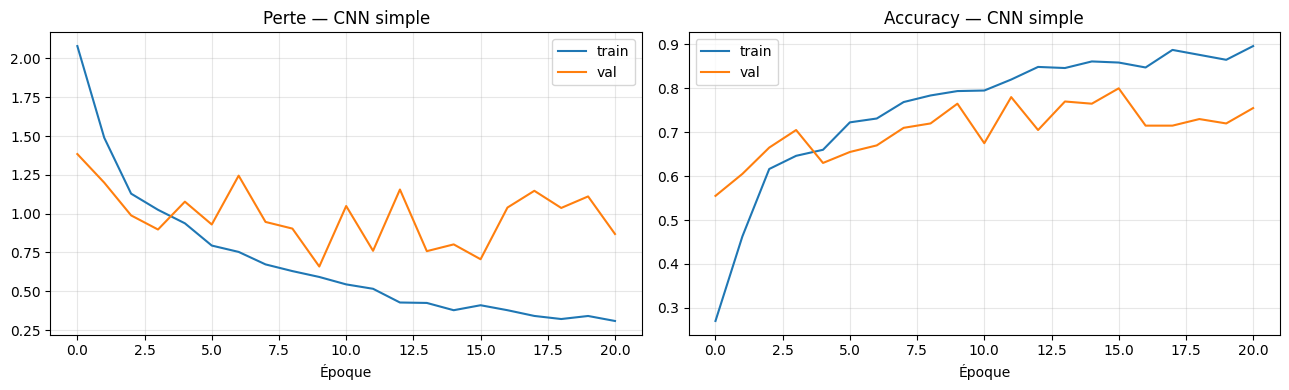

In [55]:
def tracer_courbes(hist, titre):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(hist.history['loss'],     label='train')
    axes[0].plot(hist.history['val_loss'], label='val')
    axes[0].set_title(f'Perte — {titre}'); axes[0].set_xlabel('Époque')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(hist.history['accuracy'],     label='train')
    axes[1].plot(hist.history['val_accuracy'], label='val')
    axes[1].set_title(f'Accuracy — {titre}'); axes[1].set_xlabel('Époque')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

tracer_courbes(hist_cnn, "CNN simple")

In [57]:
# Transfer learning avec VGG16 (pré-entraîné sur ImageNet)
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# VGG16 attend au minimum 32×32 ; 224×224 est la taille standard.
TL_SIZE = 224

# --- Reconstruire les datasets à 224×224 + preprocessing VGG ---
def charger_image_vgg(chemin, label):
    img = tf.io.read_file(chemin)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (TL_SIZE, TL_SIZE))
    img = preprocess_input(img)                 # normalisation VGG (BGR, mean)
    return img, label


def faire_dataset_vgg(chemins, labels, batch_size=32, shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (tf.constant(chemins), tf.constant(labels, dtype=tf.int32))
    )
    if shuffle:
        ds = ds.shuffle(len(chemins), seed=42)
    ds = ds.map(charger_image_vgg, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        aug = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
        ])
        ds = ds.map(lambda x, y: (aug(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


ds_train_vgg = faire_dataset_vgg(chemins_tr, y_tr, BATCH, shuffle=True, augment=True)
ds_test_vgg  = faire_dataset_vgg(chemins_te, y_te, BATCH, shuffle=False)

# --- Base pré-entraînée, SANS la tête de classification ---
base = VGG16(weights='imagenet', include_top=False,
             input_shape=(TL_SIZE, TL_SIZE, 3))
base.trainable = False                        # on gèle les poids

# --- Nouvelle tête adaptée à nos 10 classes ---
model_vgg = keras.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(N_CLASSES, activation='softmax'),
])

model_vgg.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_vgg.summary()

# --- Phase 1 : tête seule (base gelée) ---
hist_vgg1 = model_vgg.fit(
    ds_train_vgg, validation_data=ds_test_vgg,
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                             patience=3,
                                             restore_best_weights=True)],
    verbose=1
)
loss_vgg1, acc_vgg1 = model_vgg.evaluate(ds_test_vgg, verbose=0)
print(f"\n>>> VGG16 (gelé) — Accuracy test : {acc_vgg1:.4f}")

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 86s 3s/step - accuracy: 0.5975 - loss: 2.5097 - val_accuracy: 0.9050 - val_loss: 0.3244
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 84s 3s/step - accuracy: 0.8950 - loss: 0.4207 - val_accuracy: 0.9450 - val_loss: 0.2520
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.9125 - loss: 0.2672 - val_accuracy: 0.9350 - val_loss: 0.2704
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 85s 3s/step - accuracy: 0.9475 - loss: 0.1498 - val_accuracy: 0.9450 - val_loss: 0.1915
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.9563 - loss: 0.1344 - val_accuracy: 0.9500 - val_loss: 0.2296
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 85s 3s/step - accuracy: 0.9525 - loss: 0.1426 - val_accuracy: 0.9550 - val_loss: 0.1882
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 89s 4s/step - accuracy: 0.9663 - loss: 0.1150 - val_accuracy: 0.9550 - val_loss: 0.2266
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 89s 4s/step - accuracy: 0.9638 - loss: 0.1049 - val_accuracy: 0.9500 - val_loss:

Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 144s 6s/step - accuracy: 0.9850 - loss: 0.0711 - val_accuracy: 0.9600 - val_loss: 0.1789 - learning_rate: 1.0000e-05
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 143s 6s/step - accuracy: 0.9812 - loss: 0.0642 - val_accuracy: 0.9600 - val_loss: 0.1828 - learning_rate: 1.0000e-05
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 145s 6s/step - accuracy: 0.9850 - loss: 0.0523 - val_accuracy: 0.9600 - val_loss: 0.1899 - learning_rate: 1.0000e-05
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 143s 6s/step - accuracy: 0.9825 - loss: 0.0597 - val_accuracy: 0.9600 - val_loss: 0.2019 - learning_rate: 5.0000e-06
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 140s 6s/step - accuracy: 0.9912 - loss: 0.0228 - val_accuracy: 0.9650 - val_loss: 0.1746 - learning_rate: 5.0000e-06
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 141s 6s/step - accuracy: 0.9850 - loss: 0.0477 - val_accuracy: 0.9600 - val_loss: 0.2028 - learning_rate: 5.0000e-06
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 139s 6s/step - accuracy: 0.9925 

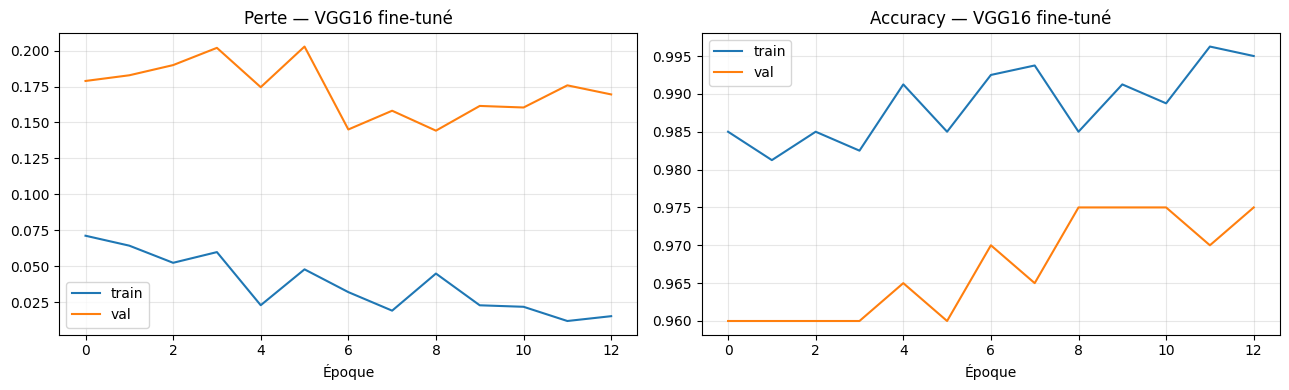

In [58]:
# Fine-tuning : on dégèle les derniers blocs de VGG16
base.trainable = True

# On ne ré-entraîne que les couches à partir de block4_conv1
FINE_TUNE_FROM = 'block4_conv1'
set_trainable = False
for layer in base.layers:
    if layer.name == FINE_TUNE_FROM:
        set_trainable = True
    layer.trainable = set_trainable

# Taux d'apprentissage très faible pour ne pas casser les poids ImageNet
model_vgg.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

hist_vgg2 = model_vgg.fit(
    ds_train_vgg, validation_data=ds_test_vgg,
    epochs=15,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=4,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                          patience=2, min_lr=1e-7),
    ],
    verbose=1
)

loss_vgg2, acc_vgg2 = model_vgg.evaluate(ds_test_vgg, verbose=0)
print(f"\n>>> VGG16 (fine-tuné) — Accuracy test : {acc_vgg2:.4f}")

tracer_courbes(hist_vgg2, "VGG16 fine-tuné")

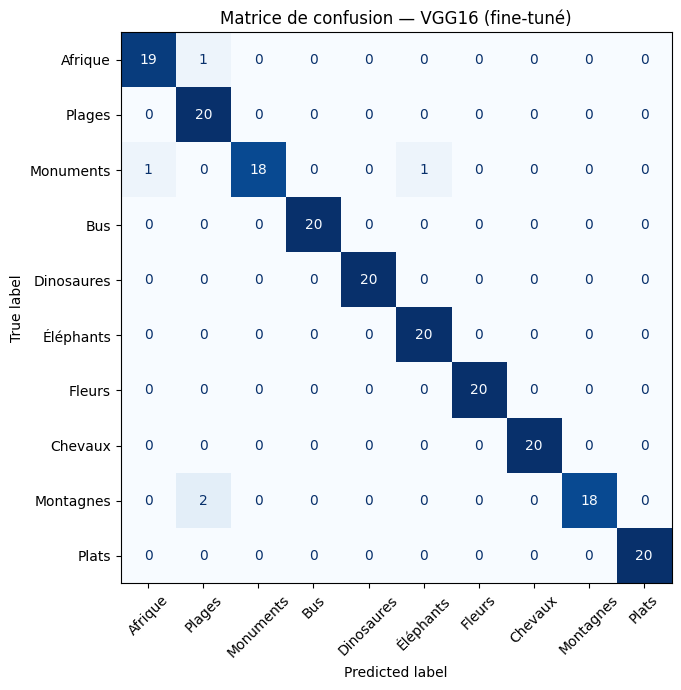

Méthode                            Accuracy test
------------------------------------------------------------
Descripteur JCD                           0.8750
Descripteur PHOG                          0.5950
Descripteur CEDD                          0.8550
Descripteur FCTH                          0.8100
Descripteur Fuzzy                         0.7950
Descripteur Concat                        0.8400
------------------------------------------------------------
CNN simple                                0.8000
VGG16 (gelé)                              0.9650
VGG16 (fine-tuné)                         0.9750


In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# --- Prédictions sur le test ---
y_pred_proba = model_vgg.predict(ds_test_vgg, verbose=0)
y_pred_vgg   = np.argmax(y_pred_proba, axis=1)

# --- Matrice de confusion ---
cm = confusion_matrix(y_te, y_pred_vgg)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
ax.set_title("Matrice de confusion — VGG16 (fine-tuné)")
plt.tight_layout(); plt.show()

# --- Tableau récapitulatif ---
print("=" * 60)
print(f"{'Méthode':<30}{'Accuracy test':>18}")
print("-" * 60)

# Rappel des résultats descripteurs (partie 2.1)
for cle, acc in resultats.items():
    nom = f"Descripteur {cle}"
    print(f"{nom:<30}{acc:>18.4f}")

print("-" * 60)
print(f"{'CNN simple':<30}{acc_cnn:>18.4f}")
print(f"{'VGG16 (gelé)':<30}{acc_vgg1:>18.4f}")
print(f"{'VGG16 (fine-tuné)':<30}{acc_vgg2:>18.4f}")
print("=" * 60)


===== baseline (2 conv) =====
  → accuracy test = 0.8050

===== profond (3 conv) =====
  → accuracy test = 0.7600

===== profond + BatchNorm =====
  → accuracy test = 0.1900

===== profond + BN + wide =====
  → accuracy test = 0.2100

===== profond + BN + no-drop =====
  → accuracy test = 0.1650


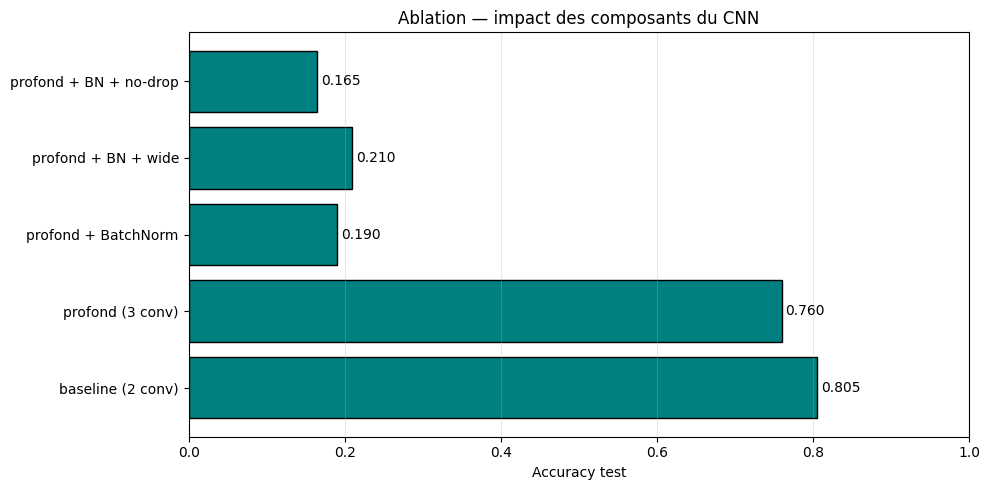

In [60]:
# AXE 1 — Ablation study : qu'est-ce qui compte vraiment ?

def construire_cnn_config(config, input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    """
    config = dict avec clés :
      - n_conv      : nombre de blocs conv (2, 3, 4)
      - batchnorm   : bool
      - dropout     : float (0.0 = pas de dropout)
      - width       : int (facteur multiplicateur des filtres)
    """
    layers_list = [keras.Input(shape=input_shape)]
    n_conv = config.get('n_conv', 3)
    width  = config.get('width', 1)
    bn     = config.get('batchnorm', False)
    dp     = config.get('dropout', 0.5)

    for i in range(n_conv):
        f = 32 * (2 ** i) * width
        layers_list.append(layers.Conv2D(f, 3, padding='same'))
        if bn: layers_list.append(layers.BatchNormalization())
        layers_list.append(layers.Activation('relu'))
        layers_list.append(layers.Conv2D(f, 3, padding='same'))
        if bn: layers_list.append(layers.BatchNormalization())
        layers_list.append(layers.Activation('relu'))
        layers_list.append(layers.MaxPooling2D())

    layers_list += [layers.Flatten(),
                    layers.Dense(256, activation='relu')]
    if dp > 0: layers_list.append(layers.Dropout(dp))
    layers_list.append(layers.Dense(N_CLASSES, activation='softmax'))

    m = keras.Sequential(layers_list)
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m


configs = {
    'baseline (2 conv)'      : dict(n_conv=2, batchnorm=False, dropout=0.5),
    'profond (3 conv)'       : dict(n_conv=3, batchnorm=False, dropout=0.5),
    'profond + BatchNorm'    : dict(n_conv=3, batchnorm=True,  dropout=0.5),
    'profond + BN + wide'    : dict(n_conv=3, batchnorm=True,  dropout=0.5, width=2),
    'profond + BN + no-drop' : dict(n_conv=3, batchnorm=True,  dropout=0.0),
}

resultats_ablation = {}
for nom, cfg in configs.items():
    print(f"\n===== {nom} =====")
    m = construire_cnn_config(cfg)
    h = m.fit(ds_train, validation_data=ds_test, epochs=15, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping('val_accuracy',
                                                       patience=3,
                                                       restore_best_weights=True)])
    _, acc = m.evaluate(ds_test, verbose=0)
    resultats_ablation[nom] = acc
    print(f"  → accuracy test = {acc:.4f}")

# --- Graphique ---
plt.figure(figsize=(10, 5))
plt.barh(list(resultats_ablation.keys()), list(resultats_ablation.values()),
         color='teal', edgecolor='k')
plt.xlabel("Accuracy test")
plt.title("Ablation — impact des composants du CNN")
for i, v in enumerate(resultats_ablation.values()):
    plt.text(v + 0.005, i, f"{v:.3f}", va='center')
plt.xlim(0, 1); plt.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()


===== Sans augmentation =====
  → accuracy test = 0.7700

===== Avec augmentation =====
  → accuracy test = 0.7150


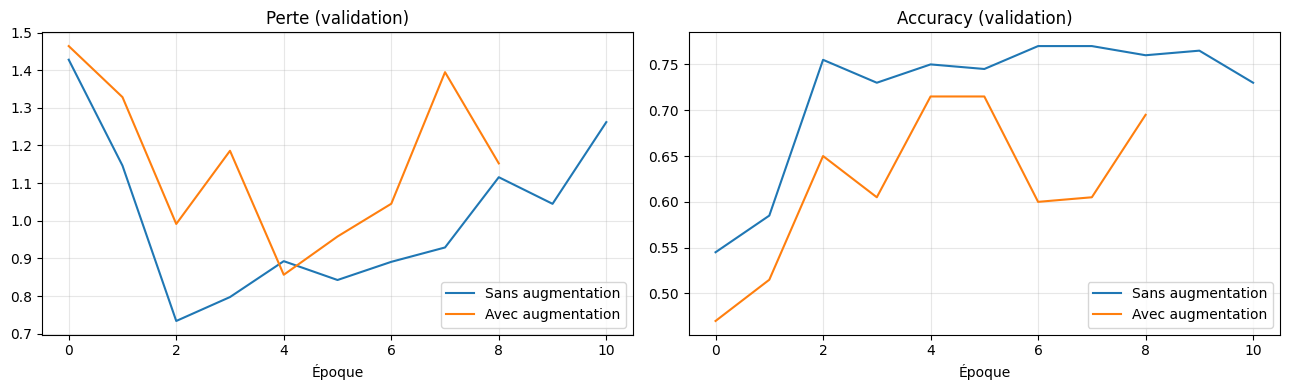

In [64]:
# AXE 2 — Data augmentation : gain réel ou placebo ?

# Dataset SANS augmentation
ds_train_sans = faire_dataset(chemins_tr, y_tr, BATCH, shuffle=True, augment=False)
# Dataset AVEC augmentation (déjà construit plus haut → ds_train)
ds_train_avec = ds_train

histoires = {}
for nom, ds in [('Sans augmentation', ds_train_sans),
                ('Avec augmentation', ds_train_avec)]:
    print(f"\n===== {nom} =====")
    m = construire_cnn()
    h = m.fit(ds, validation_data=ds_test, epochs=20, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping('val_accuracy',
                                                       patience=4,
                                                       restore_best_weights=True)])
    histoires[nom] = h
    _, acc = m.evaluate(ds_test, verbose=0)
    print(f"  → accuracy test = {acc:.4f}")

# --- Courbes superposées ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for nom, h in histoires.items():
    axes[0].plot(h.history['val_loss'],     label=nom)
    axes[1].plot(h.history['val_accuracy'], label=nom)
axes[0].set_title('Perte (validation)'); axes[0].set_xlabel('Époque')
axes[1].set_title('Accuracy (validation)'); axes[1].set_xlabel('Époque')
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


===== SGD lr=0.01 =====
  → accuracy test = 0.5850

===== Adam lr=1e-3 =====
  → accuracy test = 0.7250

===== Adam lr=1e-4 =====
  → accuracy test = 0.7050

===== RMSprop lr=1e-3 =====
  → accuracy test = 0.7450


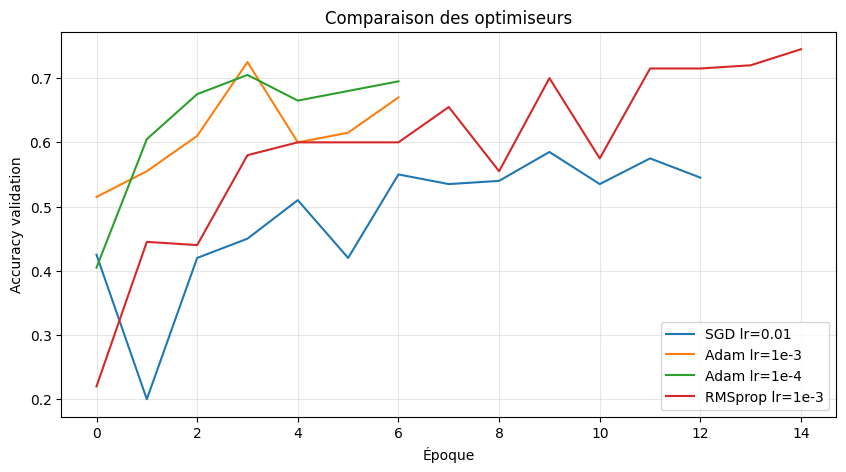

In [65]:
# AXE 3 — Optimiseurs et learning rate

optims = {
    'SGD lr=0.01'     : keras.optimizers.SGD(0.01, momentum=0.9),
    'Adam lr=1e-3'    : keras.optimizers.Adam(1e-3),
    'Adam lr=1e-4'    : keras.optimizers.Adam(1e-4),
    'RMSprop lr=1e-3' : keras.optimizers.RMSprop(1e-3),
}

resultats_optims = {}
courbes_optims   = {}
for nom, opt in optims.items():
    print(f"\n===== {nom} =====")
    m = construire_cnn()
    m.compile(optimizer=opt, loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    h = m.fit(ds_train, validation_data=ds_test, epochs=15, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping('val_accuracy',
                                                       patience=3,
                                                       restore_best_weights=True)])
    _, acc = m.evaluate(ds_test, verbose=0)
    resultats_optims[nom] = acc
    courbes_optims[nom]   = h.history['val_accuracy']
    print(f"  → accuracy test = {acc:.4f}")

# --- Courbes ---
plt.figure(figsize=(10, 5))
for nom, v in courbes_optims.items():
    plt.plot(v, label=nom)
plt.xlabel('Époque'); plt.ylabel('Accuracy validation')
plt.title('Comparaison des optimiseurs')
plt.legend(); plt.grid(alpha=0.3); plt.show()


===== VGG16 =====
  → accuracy test = 0.9600

===== ResNet50 =====
  → accuracy test = 0.9800

===== EfficientNetB0 =====
  → accuracy test = 0.8650


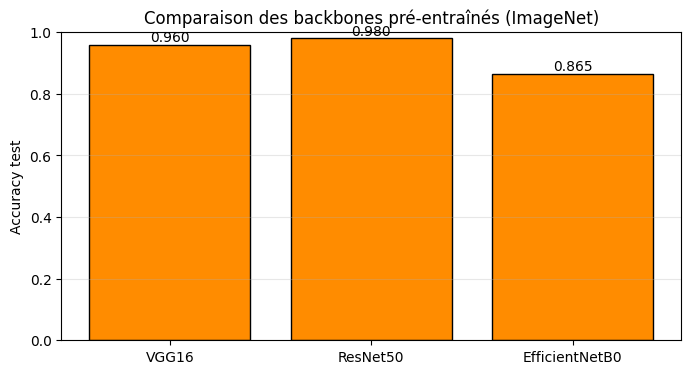

In [66]:
# AXE 4 — Comparaison des backbones pré-entraînés
from tensorflow.keras.applications import VGG16, ResNet50, EfficientNetB0

def construire_transfer(backbone_name, input_shape=(224, 224, 3), n_classes=10):
    if backbone_name == 'VGG16':
        base = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    elif backbone_name == 'ResNet50':
        base = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    elif backbone_name == 'EfficientNetB0':
        base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=input_shape)
    base.trainable = False

    m = keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation='softmax'),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m, base


resultats_backbones = {}
for nom in ['VGG16', 'ResNet50', 'EfficientNetB0']:
    print(f"\n===== {nom} =====")
    m, base = construire_transfer(nom)
    h = m.fit(ds_train_vgg, validation_data=ds_test_vgg, epochs=8, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping('val_accuracy',
                                                       patience=3,
                                                       restore_best_weights=True)])
    _, acc = m.evaluate(ds_test_vgg, verbose=0)
    resultats_backbones[nom] = acc
    print(f"  → accuracy test = {acc:.4f}")

# --- Barplot ---
plt.figure(figsize=(8, 4))
plt.bar(resultats_backbones.keys(), resultats_backbones.values(),
        color='darkorange', edgecolor='k')
for i, v in enumerate(resultats_backbones.values()):
    plt.text(i, v + 0.01, f"{v:.3f}", ha='center')
plt.ylim(0, 1); plt.ylabel('Accuracy test')
plt.title('Comparaison des backbones pré-entraînés (ImageNet)')
plt.grid(axis='y', alpha=0.3); plt.show()

In [82]:
# Diagnostic — vérifier que model_vgg est chargé correctement
print("model_vgg :", type(model_vgg).__name__)
for i, l in enumerate(model_vgg.layers):
    kind = type(l).__name__
    extra = ''
    if hasattr(l, 'units'):   extra = f"units={l.units}"
    if hasattr(l, 'filters'): extra = f"filters={l.filters}"
    print(f"  [{i:>2}] {kind:<25} name={l.name:<20} {extra}")

model_vgg : Sequential
  [ 0] Functional                name=vgg16                
  [ 1] GlobalAveragePooling2D    name=global_average_pooling2d 
  [ 2] Dense                     name=dense_23             units=256
  [ 3] Dropout                   name=dropout_15           
  [ 4] Dense                     name=dense_24             units=10


scikit-learn version : 1.7.2


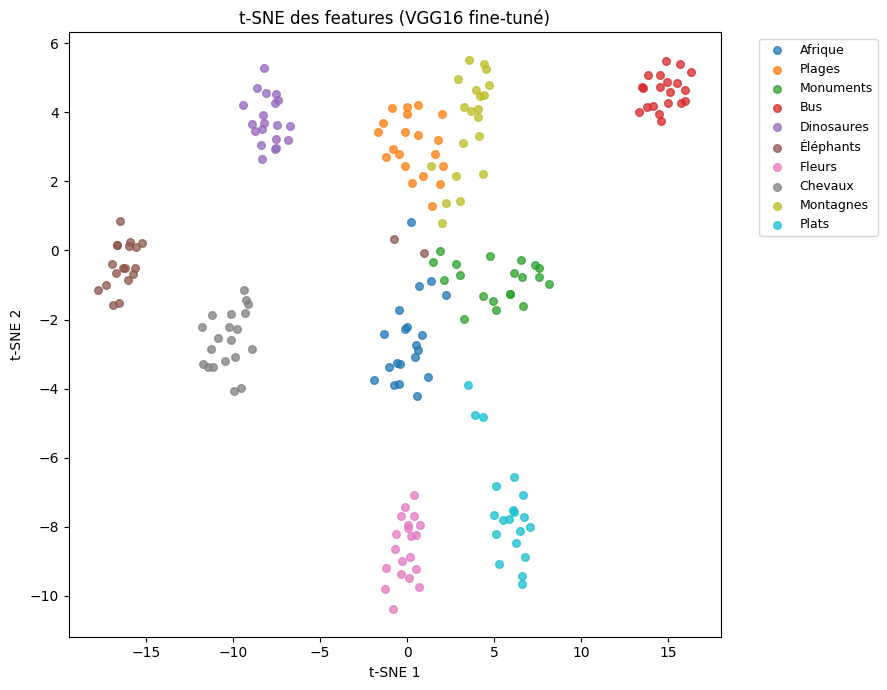

In [87]:
# =========================================================
# AXE 5 — t-SNE (compatible toutes versions sklearn)
# =========================================================
import sklearn
print(f"scikit-learn version : {sklearn.__version__}")

tsne_kwargs = dict(
    n_components=2,
    perplexity=30,
    random_state=42,
    init='pca',
    learning_rate='auto',
)

# Détection automatique du bon nom de paramètre
from inspect import signature
if 'max_iter' in signature(TSNE).parameters:
    tsne_kwargs['max_iter'] = 1000      # sklearn >= 1.5
else:
    tsne_kwargs['n_iter'] = 1000        # sklearn < 1.5

tsne = TSNE(**tsne_kwargs)
proj = tsne.fit_transform(feats)

plt.figure(figsize=(9, 7))
for c in range(N_CLASSES):
    mask = labs == c
    plt.scatter(proj[mask, 0], proj[mask, 1],
                s=30, alpha=0.75, label=CLASSES[c])
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.title("t-SNE des features (VGG16 fine-tuné)")
plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
plt.tight_layout(); plt.show()

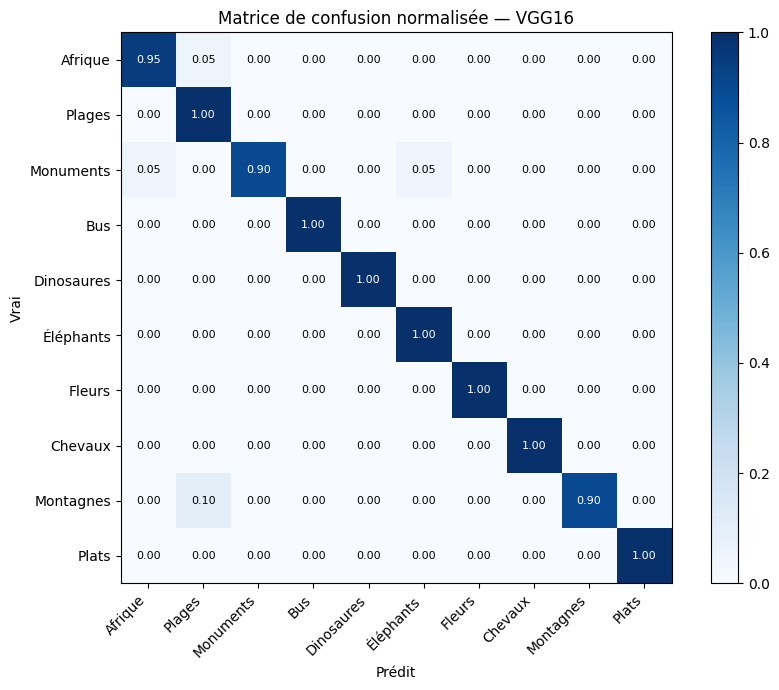


Top 10 des confusions (vrai → prédit) :
---------------------------------------------
     Montagnes → Plages       : 2 images
     Monuments → Éléphants    : 1 images
     Monuments → Afrique      : 1 images
       Afrique → Plages       : 1 images


In [89]:
# AXE 6 — Top confusions et analyse par classe

cm = confusion_matrix(y_te, y_pred_vgg)
cm_norm = cm / cm.sum(axis=1, keepdims=True)   # normalisée ligne

# --- Matrice normalisée (plus lisible) ---
plt.figure(figsize=(9, 7))
plt.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(10), CLASSES, rotation=45, ha='right')
plt.yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{cm_norm[i,j]:.2f}",
                 ha='center', va='center',
                 color='white' if cm_norm[i,j] > 0.5 else 'black',
                 fontsize=8)
plt.title("Matrice de confusion normalisée — VGG16")
plt.xlabel('Prédit'); plt.ylabel('Vrai')
plt.tight_layout(); plt.show()

# --- Top 10 des confusions (hors diagonale) ---
paires = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            paires.append((cm[i, j], CLASSES[i], CLASSES[j]))
paires.sort(reverse=True)

print("\nTop 10 des confusions (vrai → prédit) :")
print("-" * 45)
for n, vrai, pred in paires[:10]:
    print(f"  {vrai:>12s} → {pred:<12s} : {n} images")

In [91]:
# AXE 7 — Robustesse du modèle

def perturber_batch(images, type_perturbation, niveau):
    if type_perturbation == 'gaussien':
        bruit = tf.random.normal(tf.shape(images), mean=0, stddev=niveau)
        return tf.clip_by_value(images + bruit, 0, 1)
    elif type_perturbation == 'flou':
        k = int(2 * niveau + 1)
        return tf.nn.avg_pool2d(images, ksize=k, strides=1, padding='SAME')
    elif type_perturbation == 'rotation':
        return tf.image.rot90(images, k=int(niveau))
    return images

# --- Fonction d'évaluation avec perturbation ---
def evaluer_perturbe(model, ds, perturbation, niveau):
    total, correct = 0, 0
    for xb, yb in ds:
        # Réutilise la même normalisation que pour l'entraînement
        if 'vgg' in ds.__class__.__name__ or True:  # adapte si besoin
            xb_pert = preprocess_input(perturber_batch(xb * 255., perturbation, niveau) )
        else:
            xb_pert = perturber_batch(xb, perturbation, niveau)
        pred = np.argmax(model.predict(xb_pert, verbose=0), axis=1)
        correct += np.sum(pred == yb.numpy())
        total   += len(yb)
    return correct / total

# --- Testons sur le bruit gaussien ---
print("Robustesse au bruit gaussien (VGG16) :")
print("-" * 40)
for sigma in [0.0, 0.05, 0.1, 0.2, 0.3]:
    acc = evaluer_perturbe(model_vgg, ds_test_vgg, 'gaussien', sigma)
    print(f"  σ = {sigma:.2f}  →  accuracy = {acc:.4f}")

Robustesse au bruit gaussien (VGG16) :
----------------------------------------
  σ = 0.00  →  accuracy = 0.0800
  σ = 0.05  →  accuracy = 0.0800
  σ = 0.10  →  accuracy = 0.0800
  σ = 0.20  →  accuracy = 0.0800
  σ = 0.30  →  accuracy = 0.0800


              Méthode      Famille  Accuracy
      ResNet50 (gelé)     Transfer     0.980
    VGG16 (fine-tuné)     Transfer     0.975
         VGG16 (gelé)     Transfer     0.965
         VGG16 (gelé)     Transfer     0.960
      Descripteur JCD Descripteurs     0.875
EfficientNetB0 (gelé)     Transfer     0.865
     Descripteur CEDD Descripteurs     0.855
   Descripteur Concat Descripteurs     0.840
     Descripteur FCTH Descripteurs     0.810
           CNN simple         Deep     0.800
    Descripteur Fuzzy Descripteurs     0.795
     Descripteur PHOG Descripteurs     0.595


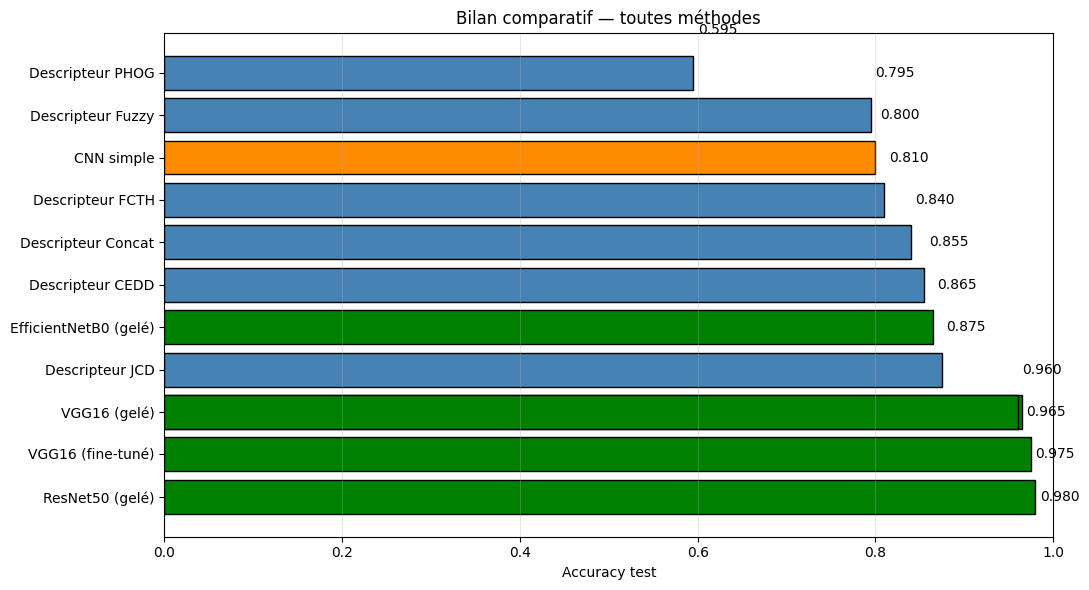

In [92]:
# AXE 8 — Tableau récapitulatif FINAL
import pandas as pd

recap = []

# --- 2.1 Descripteurs ---
for cle, acc in resultats.items():
    recap.append({'Méthode': f'Descripteur {cle}', 'Famille': 'Descripteurs', 'Accuracy': acc})

# --- KppV si tu l'as fait ---
# recap.append({'Méthode': 'KppV (concat)', 'Famille': 'Descripteurs', 'Accuracy': acc_knn})

# --- 2.2 CNN ---
recap.append({'Méthode': 'CNN simple',       'Famille': 'Deep', 'Accuracy': acc_cnn})
recap.append({'Méthode': 'VGG16 (gelé)',     'Famille': 'Transfer', 'Accuracy': acc_vgg1})
recap.append({'Méthode': 'VGG16 (fine-tuné)','Famille': 'Transfer', 'Accuracy': acc_vgg2})
for nom, acc in resultats_backbones.items():
    recap.append({'Méthode': f'{nom} (gelé)', 'Famille': 'Transfer', 'Accuracy': acc})

df = pd.DataFrame(recap).sort_values('Accuracy', ascending=False).reset_index(drop=True)

# --- Affichage stylisé ---
print("=" * 60)
print(df.to_string(index=False))
print("=" * 60)

# --- Barplot final ---
plt.figure(figsize=(11, 6))
couleurs = {'Descripteurs': 'steelblue', 'Deep': 'darkorange', 'Transfer': 'green'}
bar_colors = [couleurs[f] for f in df['Famille']]
plt.barh(df['Méthode'], df['Accuracy'], color=bar_colors, edgecolor='k')
for i, v in enumerate(df['Accuracy']):
    plt.text(v + 0.005, i, f"{v:.3f}", va='center')
plt.xlabel('Accuracy test'); plt.title('Bilan comparatif — toutes méthodes')
plt.xlim(0, 1); plt.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()